# Annotations using clustering for cells for kidney_s2

In [1]:
slide_id = "kidney_s2"

In [ ]:
import sys
from pathlib import Path
import pandas as pd
import scanpy as sc
import spatialdata as sd
import decoupler as dc

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[3]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  fro

## 1. Load the data

In [ ]:
sdata_path = get_full_path("STHELAR_HistoST", "sdata_processed", f"sdata_{slide_id}.zarr", as_str=True)
sdata = sd.read_zarr(sdata_path, selection=('tables',))
sdata

$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_labels', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


SpatialData object, with associated Zarr store: /path/to/data_legacy/data_HE2CellType/CT_DS/sdata_processed/sdata_kidney_s2.zarr
└── Tables
      └── 'table_cells': AnnData (459288, 405)
with coordinate systems:

with the following elements in the Zarr store but not in the SpatialData object:
    ▸ cell_boundaries (Shapes)
    ▸ nucleus_boundaries (Shapes)
    ▸ st (Points)
    ▸ he (Images)
    ▸ morpho (Images)

In [ ]:
adata_cells_ini = sdata.tables['table_cells'].copy()   # Always use table_cells
adata_cells_ini

AnnData object with n_obs × n_vars = 459288 × 405
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [5]:
adata_cells_ini.obs

,cell_id,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,nucleus_count,segmentation_method,region,z_level
0,aaaaaaaa-1,75,0,0,0,0,0,75,59.019221,31.970626,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0
1,aaaaaaab-1,71,0,0,0,0,0,71,85.029222,46.149689,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0
2,aaaaaaac-1,96,0,0,0,0,0,96,64.302502,40.730939,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0
3,aaaaaaad-1,154,0,0,0,0,0,154,134.746255,67.508596,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0
4,aaaaaaae-1,28,0,0,0,0,0,28,34.680001,21.268595,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
465529,aaahacbd-1,1,0,0,0,0,0,1,11.605157,11.605157,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0
465530,aaahacbe-1,8,0,0,0,0,0,8,11.289063,11.289063,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0
465531,aaahacbf-1,5,0,0,0,0,0,5,16.075626,4.967188,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0
465532,aaahacbg-1,15,0,0,0,0,0,15,24.835938,18.062501,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0


In [6]:
adata_cells_ini.var

,gene_ids,feature_types,genome
ABCC11,ENSG00000121270,Gene Expression,Unknown
ACE2,ENSG00000130234,Gene Expression,Unknown
ACKR1,ENSG00000213088,Gene Expression,Unknown
ACTA2,ENSG00000107796,Gene Expression,Unknown
ACTG2,ENSG00000163017,Gene Expression,Unknown
...,...,...,...
VIM,ENSG00000026025,Gene Expression,Unknown
VSIG4,ENSG00000155659,Gene Expression,Unknown
VSIR,ENSG00000107738,Gene Expression,Unknown
VWA5A,ENSG00000110002,Gene Expression,Unknown


## 2. Preprocessing

<Axes: >

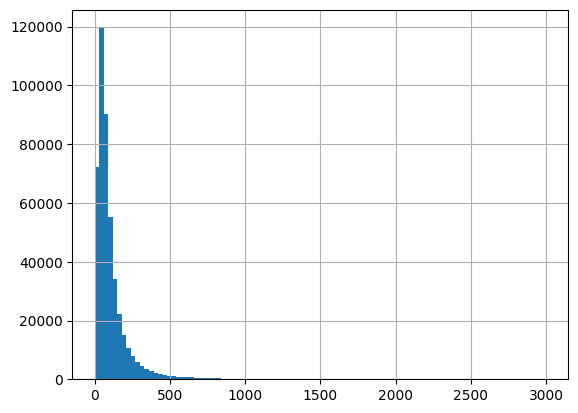

In [7]:
adata_cells_ini.obs['transcript_counts'].hist(bins=100)

<Axes: >

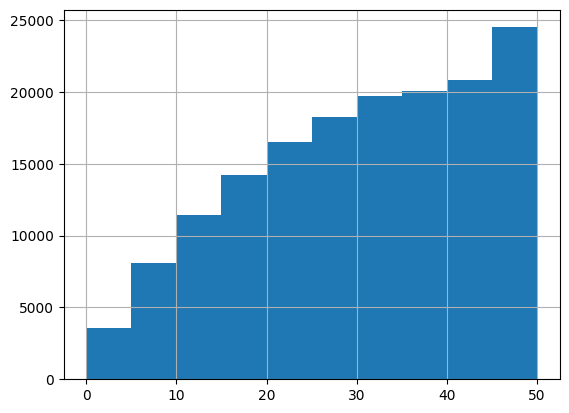

In [8]:
# in range 0-50
adata_cells_ini.obs['transcript_counts'].hist(range=(0,50))

In [9]:
print(f"Number of cells with less than 20 transcripts: {(adata_cells_ini.obs['transcript_counts']<20).sum()}")
print(f"Percentage of cells with less than 20 transcripts: {round(((adata_cells_ini.obs['transcript_counts']<20).sum())/len(adata_cells_ini.obs)*100, 2)}%")
print('-----')
print(f"Number of cells with less than 15 transcripts: {(adata_cells_ini.obs['transcript_counts']<15).sum()}")
print(f"Percentage of cells with less than 15 transcripts: {round(((adata_cells_ini.obs['transcript_counts']<15).sum())/len(adata_cells_ini.obs)*100, 2)}%")
print('-----')
print(f"Number of cells with less than 10 transcripts: {(adata_cells_ini.obs['transcript_counts']<10).sum()}")
print(f"Percentage of cells with less than 10 transcripts: {round(((adata_cells_ini.obs['transcript_counts']<10).sum())/len(adata_cells_ini.obs)*100, 2)}%")
print('-----')
print(f"Number total of cells: {len(adata_cells_ini.obs)}")

Number of cells with less than 20 transcripts: 37320
Percentage of cells with less than 20 transcripts: 8.13%
-----
Number of cells with less than 15 transcripts: 23088
Percentage of cells with less than 15 transcripts: 5.03%
-----
Number of cells with less than 10 transcripts: 11662
Percentage of cells with less than 10 transcripts: 2.54%
-----
Number total of cells: 459288


In [10]:
adata_cells =  adata_cells_ini[adata_cells_ini.obs['transcript_counts']>10].copy()
print(len(adata_cells.obs))

445614


In [11]:
# Save the raw data
adata_cells.layers['count'] = adata_cells.X.copy()

In [12]:
# Normalize
sc.pp.normalize_total(adata_cells, target_sum=1e4)
sc.pp.log1p(adata_cells)
adata_cells.layers['log_norm'] = adata_cells.X.copy()

In [13]:
# Scale each gene to unit variance. Clip values exceeding standard deviation 10.
sc.pp.scale(adata_cells, max_value=10)

$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## 3. Principal component analysis

In [14]:
# Reduce the dimensionality of the data by running principal component analysis (PCA), which reveals the main axes of variation and denoises the data.
sc.tl.pca(adata_cells, svd_solver="arpack", use_highly_variable=False)

$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


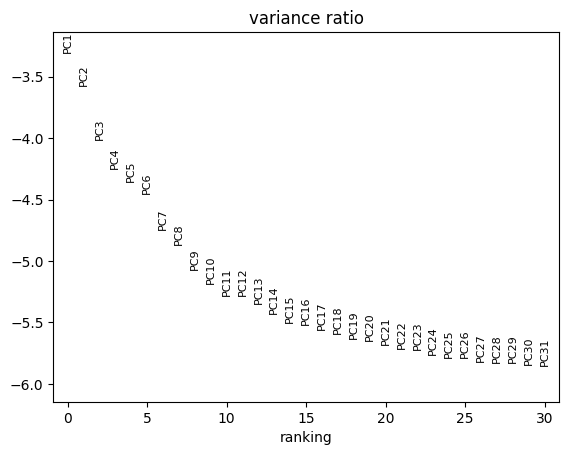

In [15]:
# Contribution of single PCs to the total variance in the data
# This indicates how many PCs to consider when computing the neighborhood relations of cells, e.g. used in the clustering function  `sc.tl.louvain()` or tSNE `sc.tl.tsne()`
sc.pl.pca_variance_ratio(adata_cells, log=True)

In [16]:
adata_cells

AnnData object with n_obs × n_vars = 445614 × 405
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level'
    var: 'gene_ids', 'feature_types', 'genome', 'mean', 'std'
    uns: 'spatialdata_attrs', 'log1p', 'pca'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    layers: 'count', 'log_norm'

In [17]:
# Restore X to be log norm counts
# All of the analysis below uses the 'log_norm' layer as input
dc.pp.swap_layer(adata_cells, key='log_norm', X_key=None, inplace=True)

## 4. The neighborhood graph + clustering

In [18]:
# Neighborhood graph of cells using the PCA representation of the data matrix
sc.pp.neighbors(adata_cells, n_neighbors=10, n_pcs=24, use_rep="X_pca", key_added='pca_n10_pcs24')
# Embedding the neighborhood graph using UMAP
sc.tl.umap(adata_cells, neighbors_key='pca_n10_pcs24')
# Leiden clustering directly clusters the neighborhood graph of cells
sc.tl.leiden(adata_cells, resolution=0.6, random_state=0, n_iterations=2, directed=False, key_added='pca_n10_pcs24_leiden_res0.6', neighbors_key='pca_n10_pcs24')
sc.tl.leiden(adata_cells, resolution=0.8, random_state=0, n_iterations=2, directed=False, key_added='pca_n10_pcs24_leiden_res0.8', neighbors_key='pca_n10_pcs24')

/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_92247/126087630.py:6: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_cells, resolution=0.6, random_state=0, n_iterations=2, directed=False, key_added='pca_n10_pcs24_leiden_res0.6', neighbors_key='pca_n10_pcs24')


... storing 'segmentation_method' as categorical
... storing 'feature_types' as categorical
... storing 'genome' as categorical


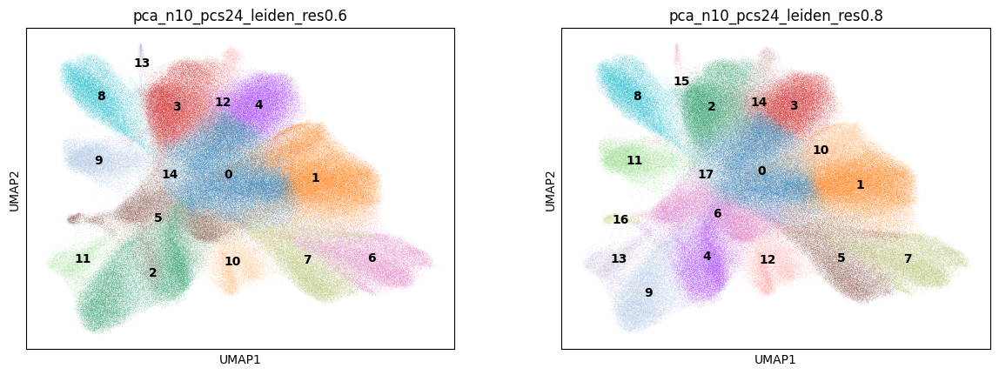

In [19]:
# Plot the clusters
sc.pl.umap(adata_cells, neighbors_key='pca_n10_pcs24',
           color=['pca_n10_pcs24_leiden_res0.6', 'pca_n10_pcs24_leiden_res0.8'],
           ncols=3, legend_loc='on data')

In [20]:
# Number of clusters
adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].unique()

['0', '14', '3', '5', '1', ..., '12', '6', '11', '8', '16']
Length: 18
Categories (18, object): ['0', '1', '2', '3', ..., '14', '15', '16', '17']

In [21]:
# Refine resolution
adata_cells.obs['refine_res'] = 'att'

adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['0']), 'refine_res'] = '0'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['1']), 'refine_res'] = '1'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['2']), 'refine_res'] = '2'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['3']), 'refine_res'] = '3'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['4']), 'refine_res'] = '4'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['5']), 'refine_res'] = '5'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['6']), 'refine_res'] = '6'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['7']), 'refine_res'] = '7'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['8']), 'refine_res'] = '8'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['9']), 'refine_res'] = '9'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['10']), 'refine_res'] = '10'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['11']), 'refine_res'] = '11'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['12']), 'refine_res'] = '12'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['13']), 'refine_res'] = '13'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['14']), 'refine_res'] = '14'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['15']), 'refine_res'] = '15'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['16']), 'refine_res'] = '16'
adata_cells.obs.loc[adata_cells.obs['pca_n10_pcs24_leiden_res0.8'].isin(['17']), 'refine_res'] = '17'

... storing 'refine_res' as categorical


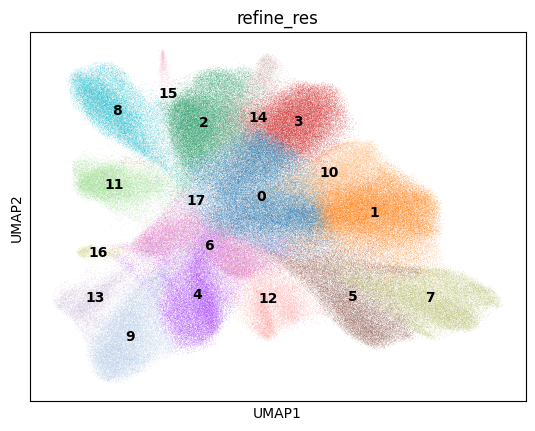

In [22]:
# Plot the clusters
sc.pl.umap(adata_cells, neighbors_key='pca_n10_pcs24', color=['refine_res'], legend_loc='on data')

## 5. Name clusters

**To go from specific gene marker to cell type: http://xteam.xbio.top/CellMarker/search.jsp?cellMarkerSpeciesType=Human&cellMarker=CD5L**

In [23]:
clustering_label = 'refine_res'

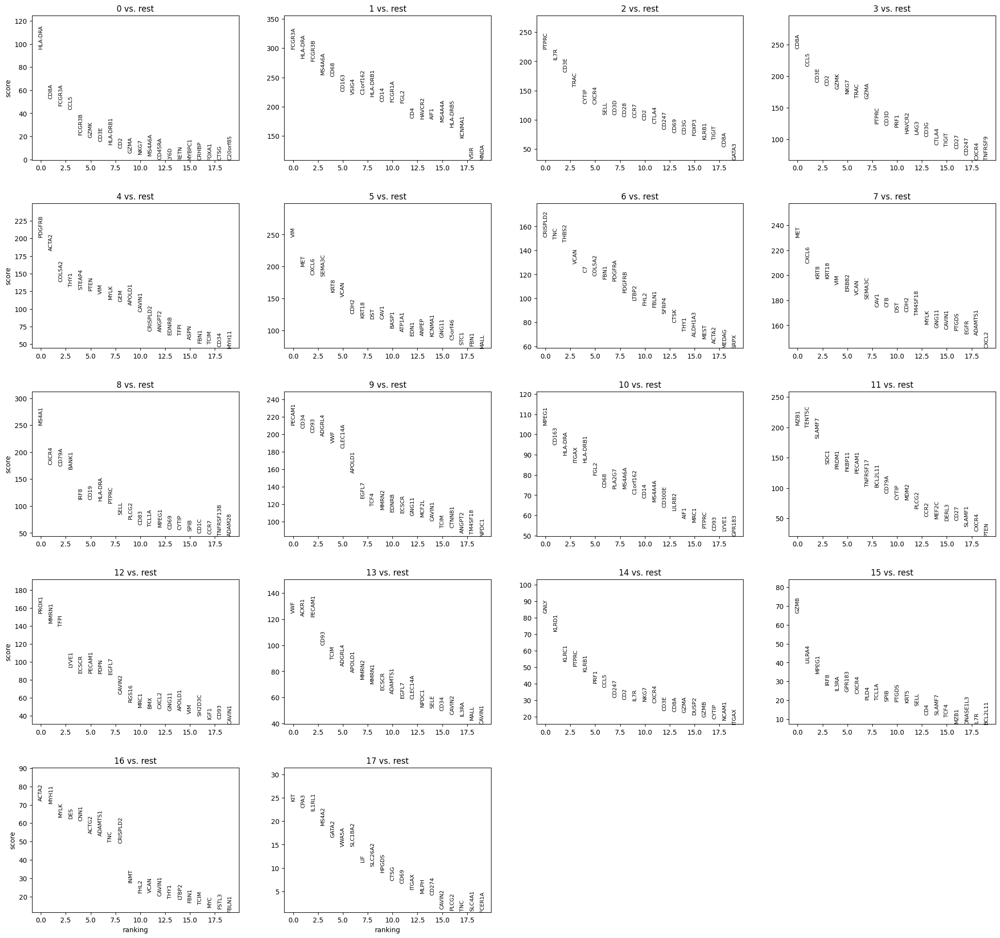

In [24]:
# Wilcoxon rank-sum (Mann-Whitney-U) test. 
# More powerful differential testing packages are also available: MAST, limma, DESeq2 and, for python, diffxpy.
sc.tl.rank_genes_groups(adata_cells, clustering_label, method="wilcoxon", corr_method="benjamini-hochberg", key_added="rank_genes_"+clustering_label)
sc.pl.rank_genes_groups(adata_cells, n_genes=20, sharey=False, key="rank_genes_"+clustering_label)

In [25]:
# The top ranked genes per cluster
top_ranked_genes = pd.DataFrame(adata_cells.uns["rank_genes_"+clustering_label]["names"]).iloc[:7, :]
list_genes = pd.concat([top_ranked_genes[col] for col in top_ranked_genes], ignore_index=True).tolist()

In [26]:
adata_cells.obs['label1'] = 'att'
adata_cells.obs['label2'] = 'att'
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

### 5.1. Cluster 0

In [27]:
cluster_id = '0'

In [28]:
top_ranked_genes[cluster_id]

0    HLA-DRA
1       CD8A
2     FCGR3A
3       CCL5
4     FCGR3B
5       GZMK
6       CD3E
Name: 0, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


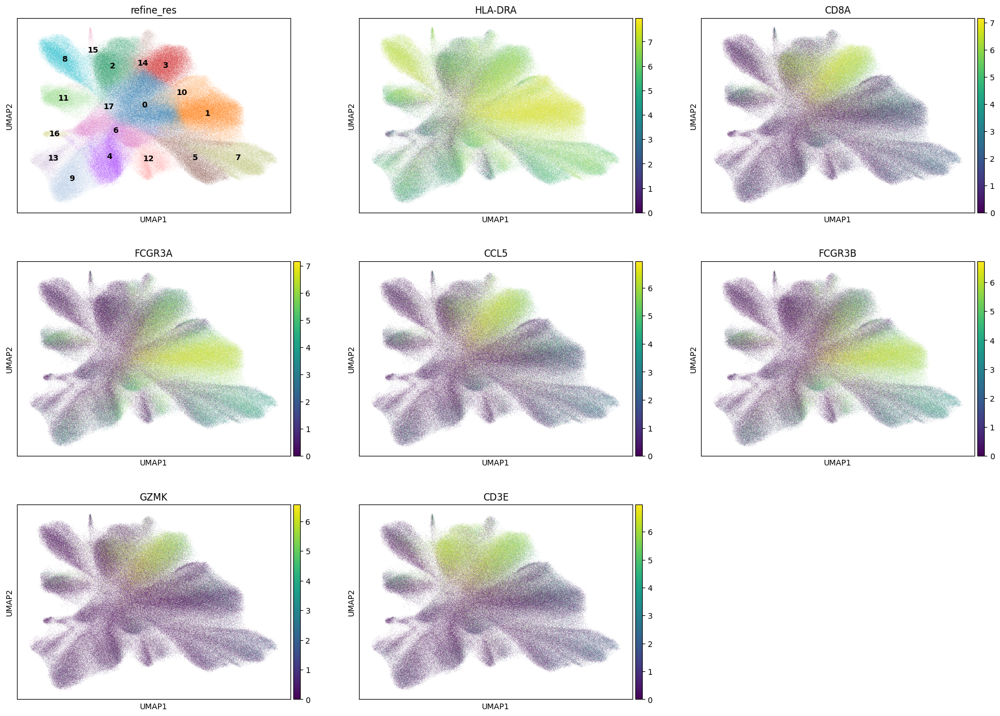

In [29]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [30]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 0: 62957
Percentage of cells in cluster 0: 14.1


In [31]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Unknown'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Unknown'

### 5.2. Cluster 1

In [32]:
cluster_id = '1'

In [33]:
top_ranked_genes[cluster_id]

0     FCGR3A
1    HLA-DRA
2     FCGR3B
3     MS4A6A
4       CD68
5      CD163
6      VSIG4
Name: 1, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


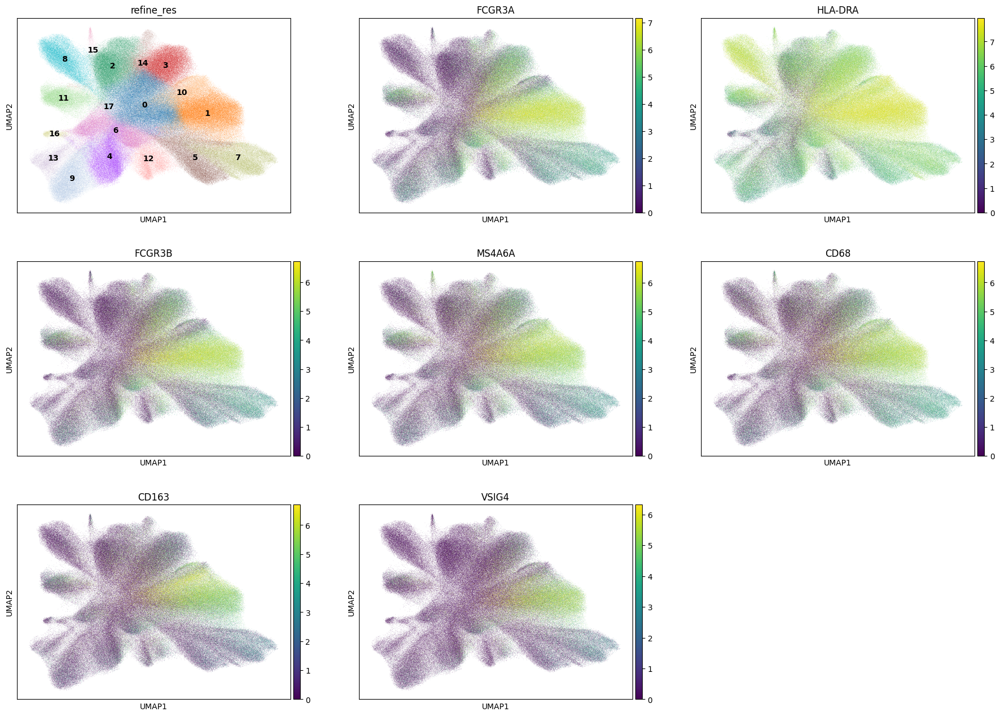

In [34]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [35]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 1: 55618
Percentage of cells in cluster 1: 12.5


In [36]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Macrophage'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'TAM'

### 5.3. Cluster 2

In [37]:
cluster_id = '2'

In [38]:
top_ranked_genes[cluster_id]

0    PTPRC
1     IL7R
2     CD3E
3     TRAC
4    CYTIP
5    CXCR4
6     SELL
Name: 2, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


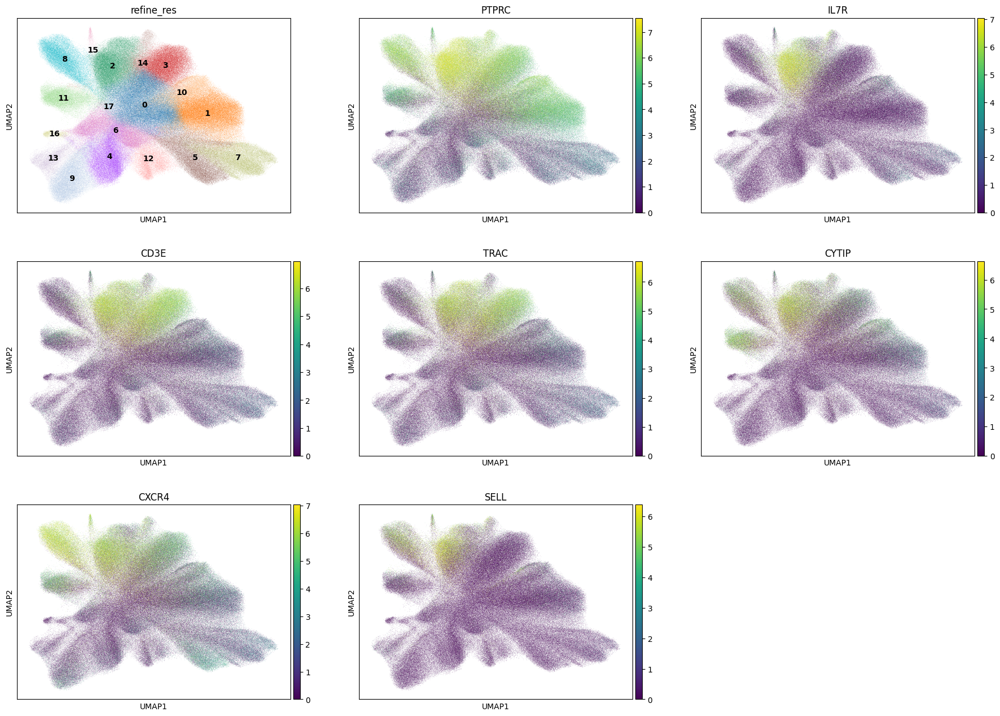

In [39]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [40]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 2: 42329
Percentage of cells in cluster 2: 9.5


In [41]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'T'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'T'

### 5.4. Cluster 3

In [42]:
cluster_id = '3'

In [43]:
top_ranked_genes[cluster_id]

0    CD8A
1    CCL5
2    CD3E
3     CD2
4    GZMK
5    NKG7
6    TRAC
Name: 3, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


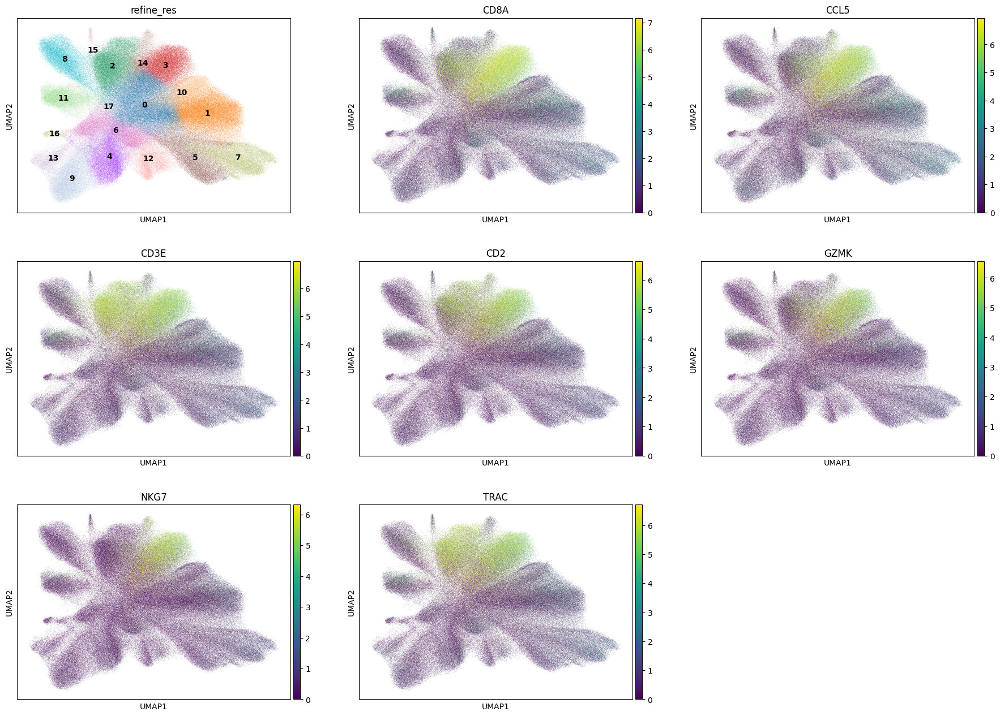

In [44]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [45]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 3: 35642
Percentage of cells in cluster 3: 8.0


In [46]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'T'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'T_CD8'

### 5.5. Cluster 4

In [47]:
cluster_id = '4'

In [48]:
top_ranked_genes[cluster_id]

0    PDGFRB
1     ACTA2
2    COL5A2
3      THY1
4    STEAP4
5      PTEN
6       VIM
Name: 4, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


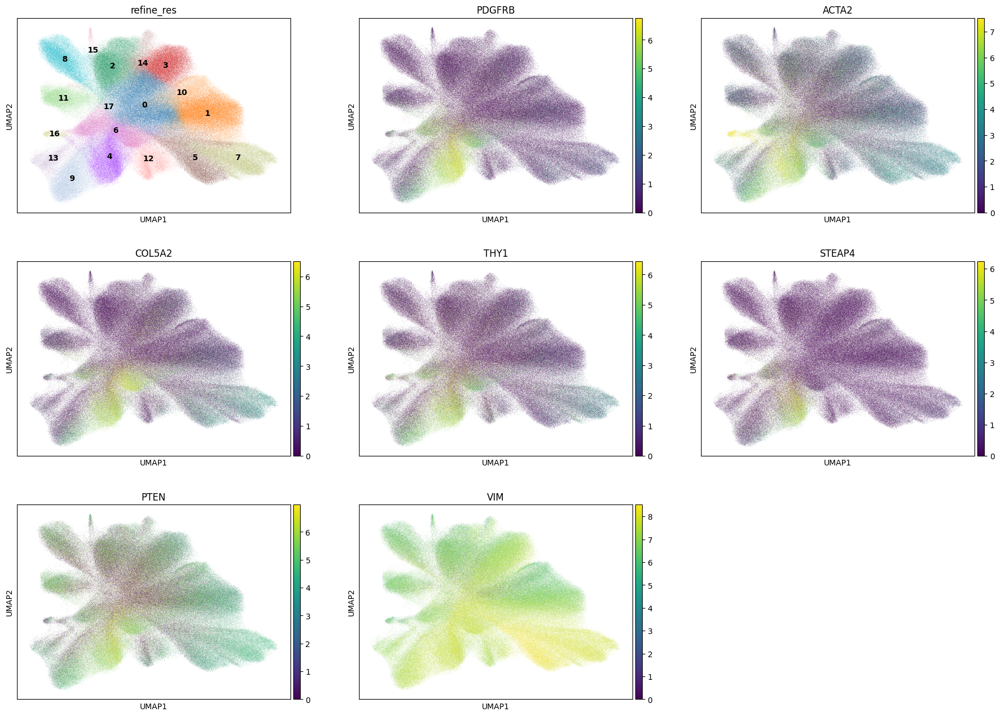

In [49]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [50]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 4: 33827
Percentage of cells in cluster 4: 7.6


In [51]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Fibroblast'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'CAF'

### 5.6. Cluster 5

In [52]:
cluster_id = '5'

In [53]:
top_ranked_genes[cluster_id]

0       VIM
1       MET
2     CXCL6
3    SEMA3C
4      KRT8
5      VCAN
6      CDH2
Name: 5, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


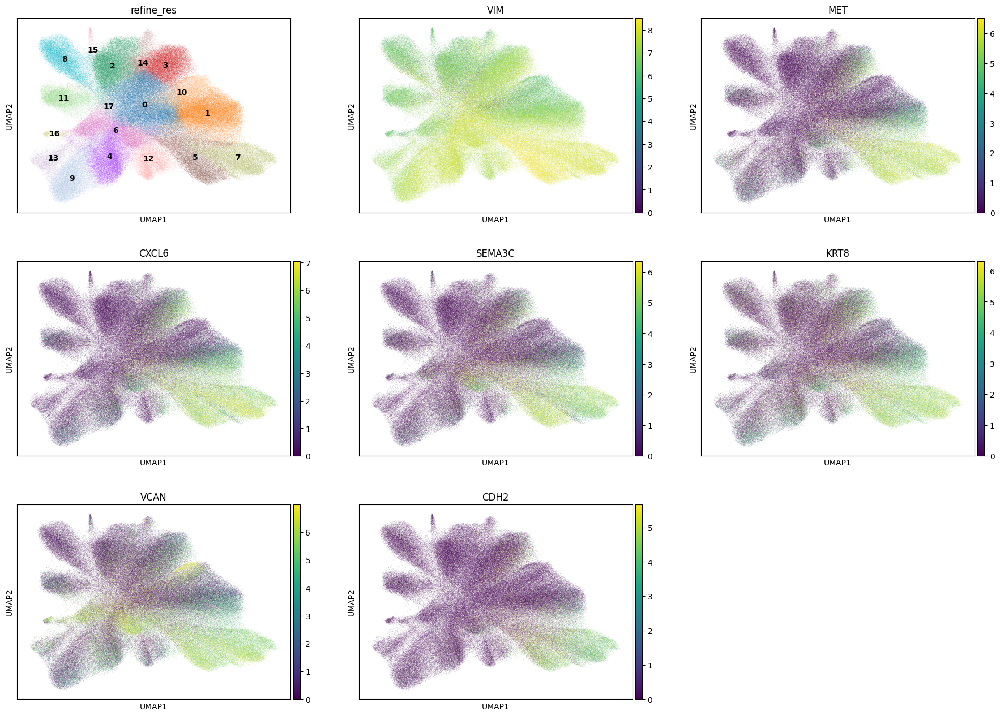

In [54]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [55]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 5: 28808
Percentage of cells in cluster 5: 6.5


In [56]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Epithelial'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Epithelial_tumor_cells'

### 5.7. Cluster 6

In [57]:
cluster_id = '6'

In [58]:
top_ranked_genes[cluster_id]

0    CRISPLD2
1         TNC
2       THBS2
3        VCAN
4          C7
5      COL5A2
6        FBN1
Name: 6, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


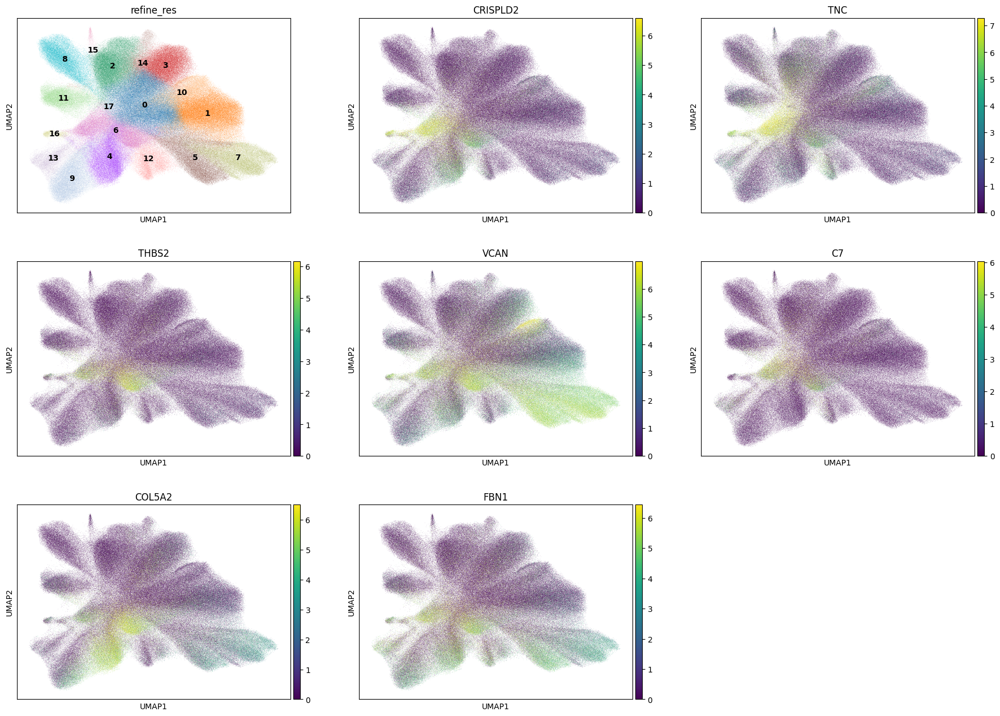

In [59]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [60]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 6: 28508
Percentage of cells in cluster 6: 6.4


In [61]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Fibroblast'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'CAF'

### 5.8. Cluster 7

In [62]:
cluster_id = '7'

In [63]:
top_ranked_genes[cluster_id]

0      MET
1    CXCL6
2     KRT8
3    KRT18
4      VIM
5    ERBB2
6     VCAN
Name: 7, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


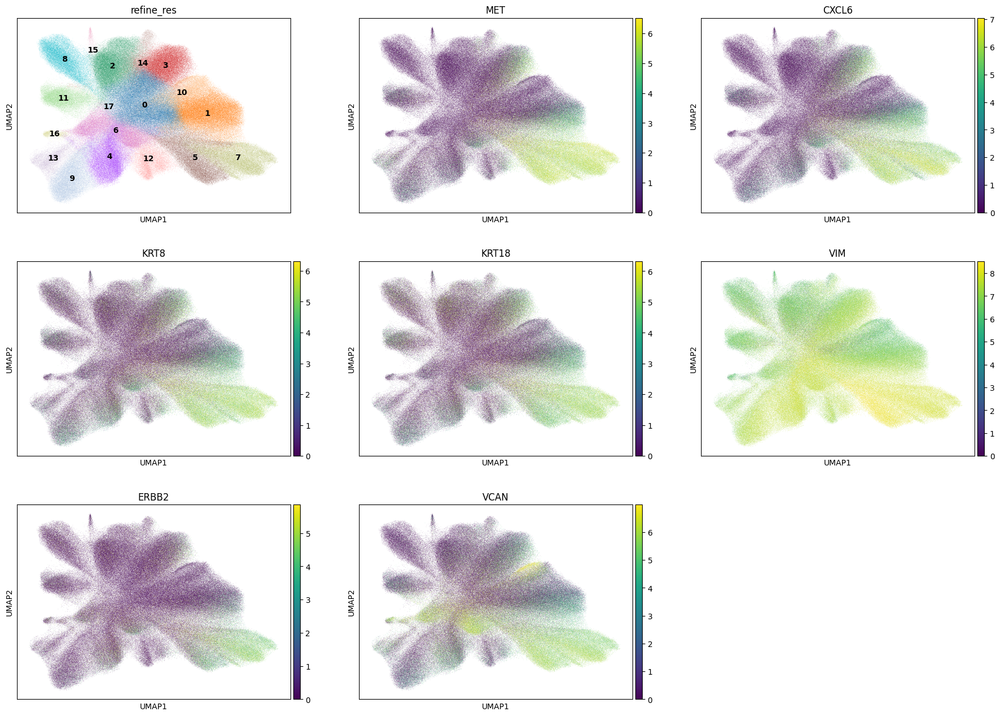

In [64]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [65]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 7: 28241
Percentage of cells in cluster 7: 6.3


In [66]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Epithelial'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Epithelial_tumor_cells'

### 5.9. Cluster 8

In [67]:
cluster_id = '8'

In [68]:
top_ranked_genes[cluster_id]

0      MS4A1
1      CXCR4
2      CD79A
3      BANK1
4       IRF8
5       CD19
6    HLA-DRA
Name: 8, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


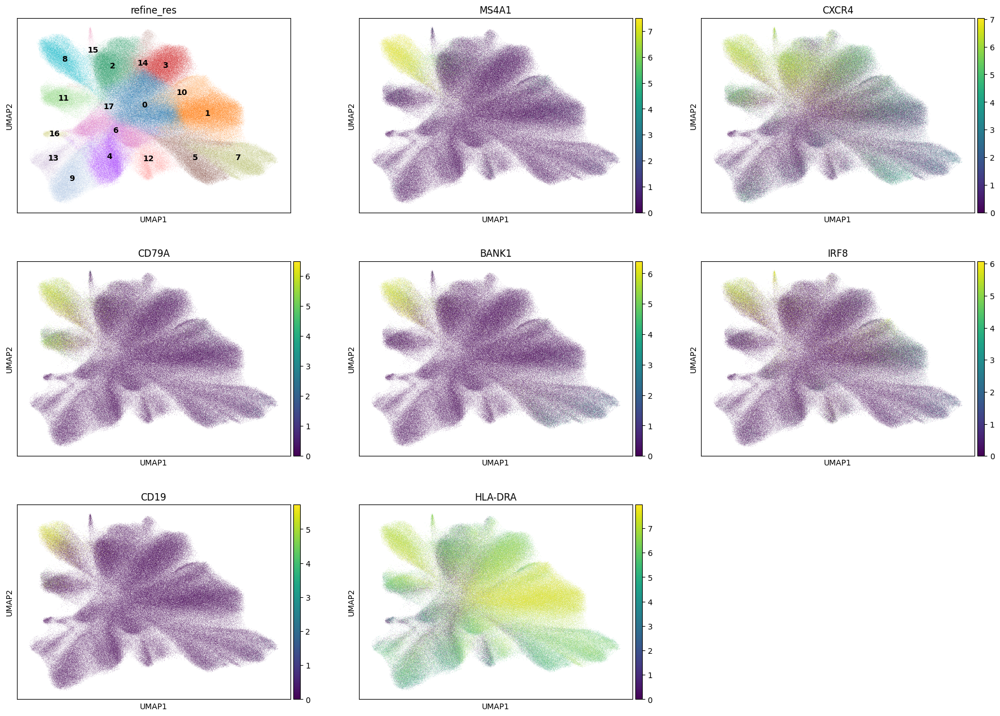

In [69]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [70]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 8: 26814
Percentage of cells in cluster 8: 6.0


In [71]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'B'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'B'

### 5.10. Cluster 9

In [72]:
cluster_id = '9'

In [73]:
top_ranked_genes[cluster_id]

0     PECAM1
1       CD34
2       CD93
3     ADGRL4
4        VWF
5    CLEC14A
6     APOLD1
Name: 9, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


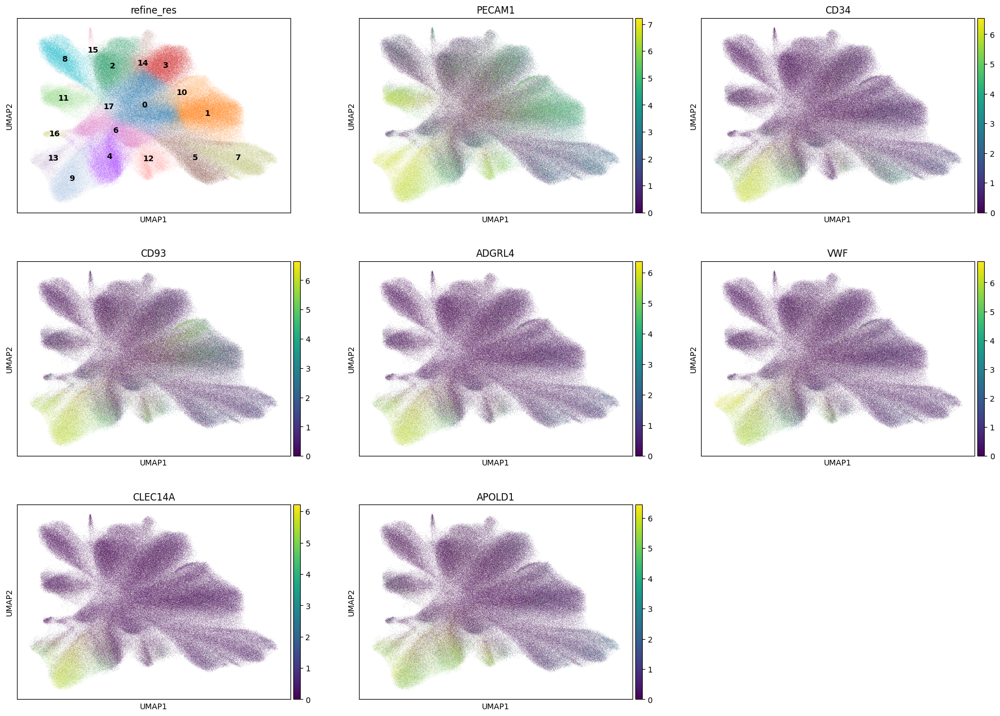

In [74]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [75]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 9: 25260
Percentage of cells in cluster 9: 5.7


In [76]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Endothelial'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Angiogenic_endothelial_cells'

### 5.11. Cluster 10

In [77]:
cluster_id = '10'

In [78]:
top_ranked_genes[cluster_id]

0       MPEG1
1       CD163
2     HLA-DRA
3       ITGAX
4    HLA-DRB1
5        FGL2
6        CD68
Name: 10, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


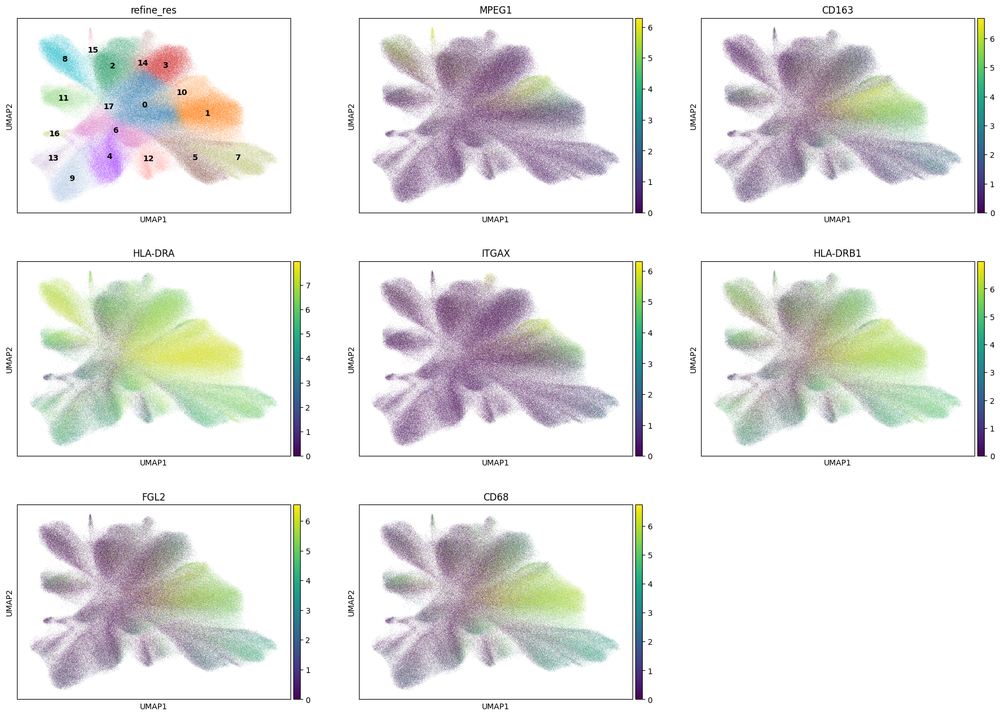

In [79]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [80]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 10: 20066
Percentage of cells in cluster 10: 4.5


In [81]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Macrophage'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'TAM'

### 5.12. Cluster 11

In [82]:
cluster_id = '11'

In [83]:
top_ranked_genes[cluster_id]

0      MZB1
1    TENT5C
2    SLAMF7
3      SDC1
4     PRDM1
5    FKBP11
6    PECAM1
Name: 11, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


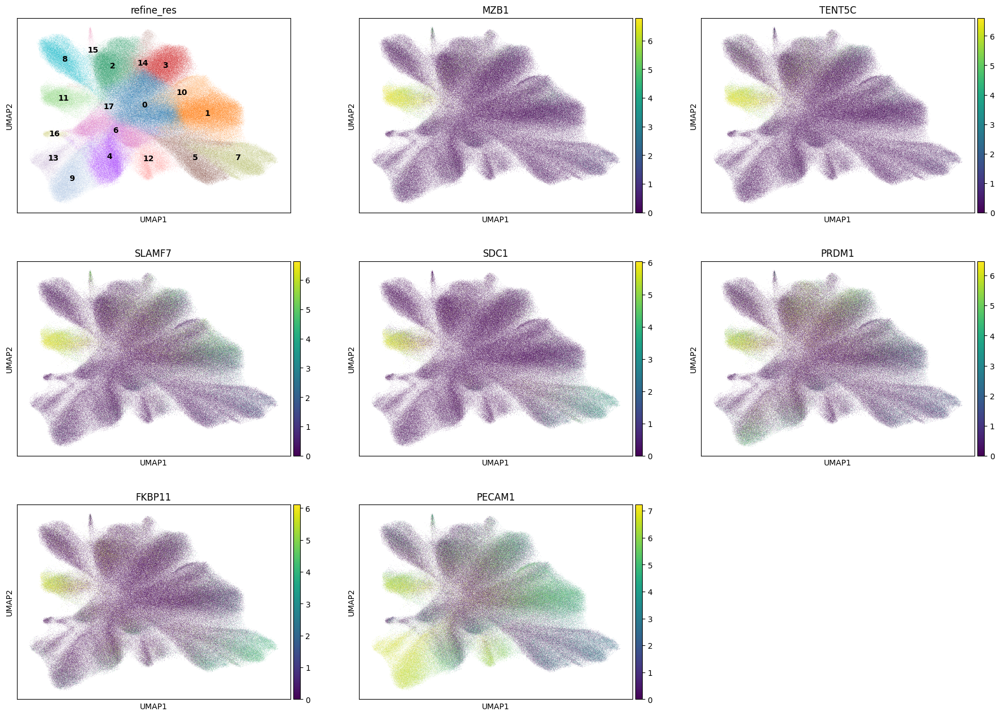

In [84]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [85]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 11: 19375
Percentage of cells in cluster 11: 4.3


In [86]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Plasma'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Plasma'

### 5.13. Cluster 12

In [87]:
cluster_id = '12'

In [88]:
top_ranked_genes[cluster_id]

0     PROX1
1     MMRN1
2      TFPI
3     LYVE1
4     ECSCR
5    PECAM1
6      PDPN
Name: 12, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


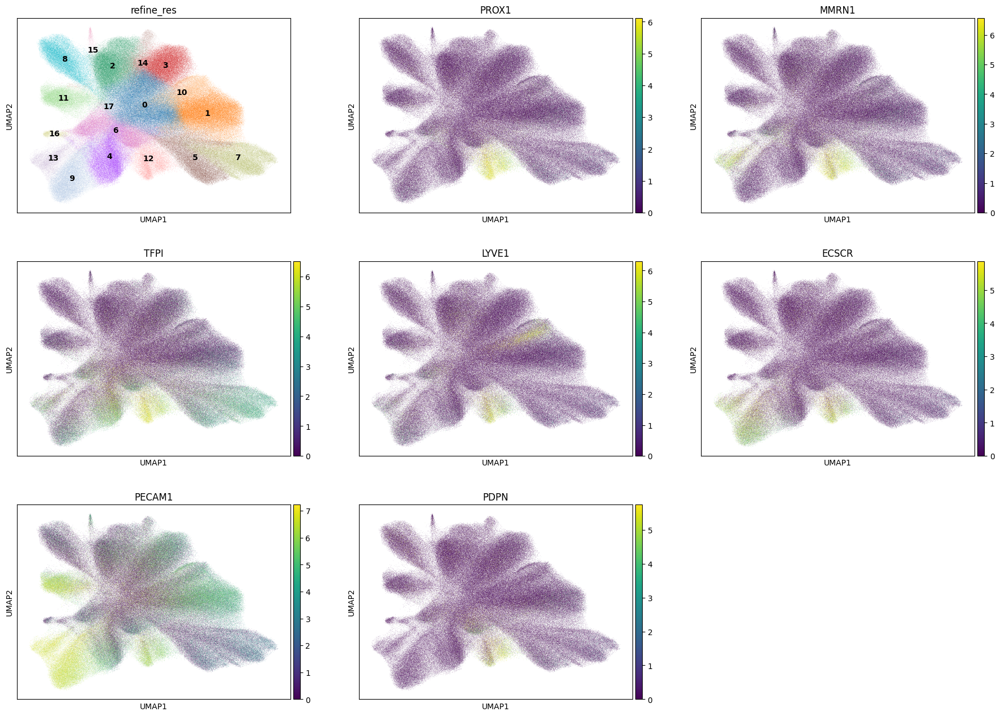

In [89]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [90]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 12: 15624
Percentage of cells in cluster 12: 3.5


In [91]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Endothelial'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Endothelial'

### 5.14. Cluster 13

In [92]:
cluster_id = '13'

In [93]:
top_ranked_genes[cluster_id]

0       VWF
1     ACKR1
2    PECAM1
3      CD93
4      TCIM
5    ADGRL4
6    APOLD1
Name: 13, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


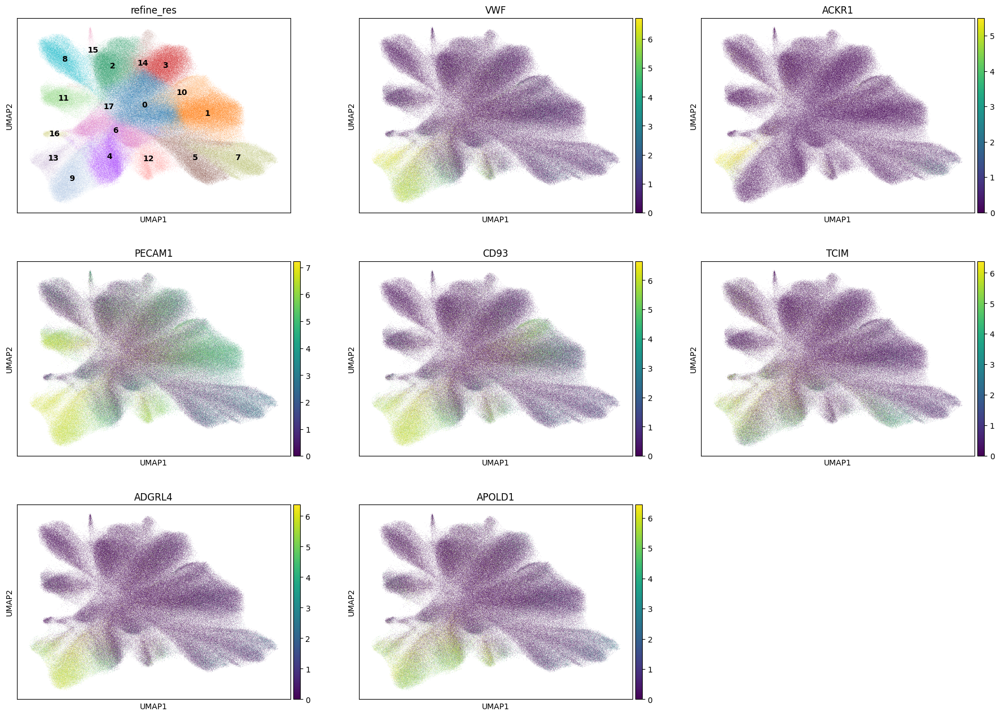

In [94]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [95]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 13: 9108
Percentage of cells in cluster 13: 2.0


In [96]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Endothelial'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Angiogenic_endothelial_cells'

### 5.15. Cluster 14

In [97]:
cluster_id = '14'

In [98]:
top_ranked_genes[cluster_id]

0     GNLY
1    KLRD1
2    KLRC1
3    PTPRC
4    KLRB1
5     PRF1
6     CCL5
Name: 14, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


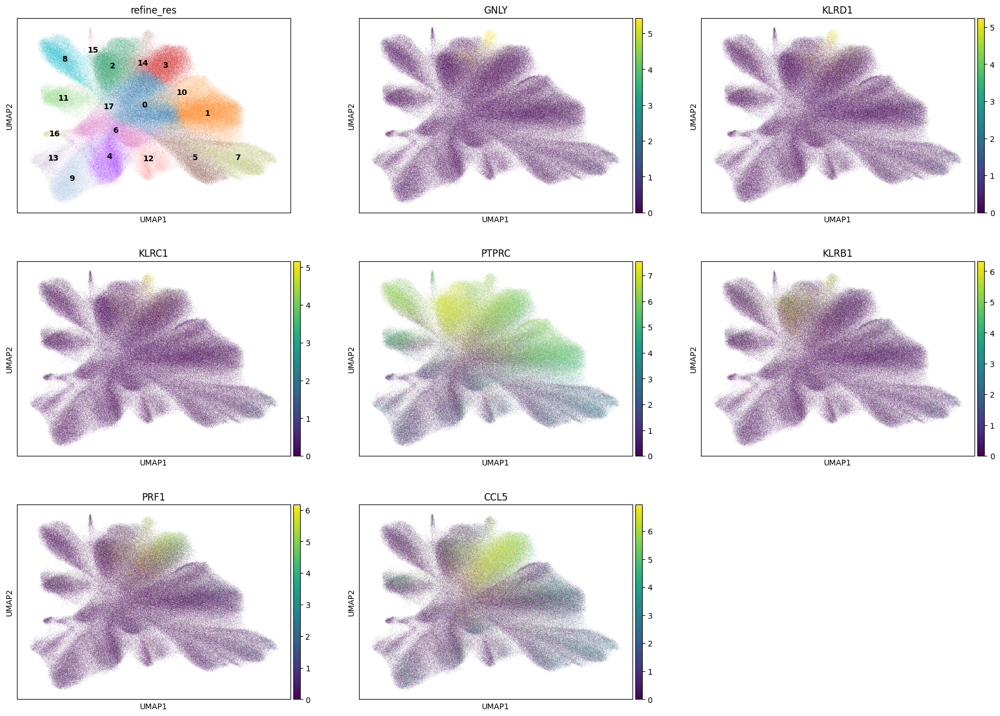

In [99]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [100]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 14: 8846
Percentage of cells in cluster 14: 2.0


In [101]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'NK'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'NK'

### 5.16. Cluster 15

In [102]:
cluster_id = '15'

In [103]:
top_ranked_genes[cluster_id]

0      GZMB
1    LILRA4
2     MPEG1
3      IRF8
4     IL3RA
5    GPR183
6     CXCR4
Name: 15, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


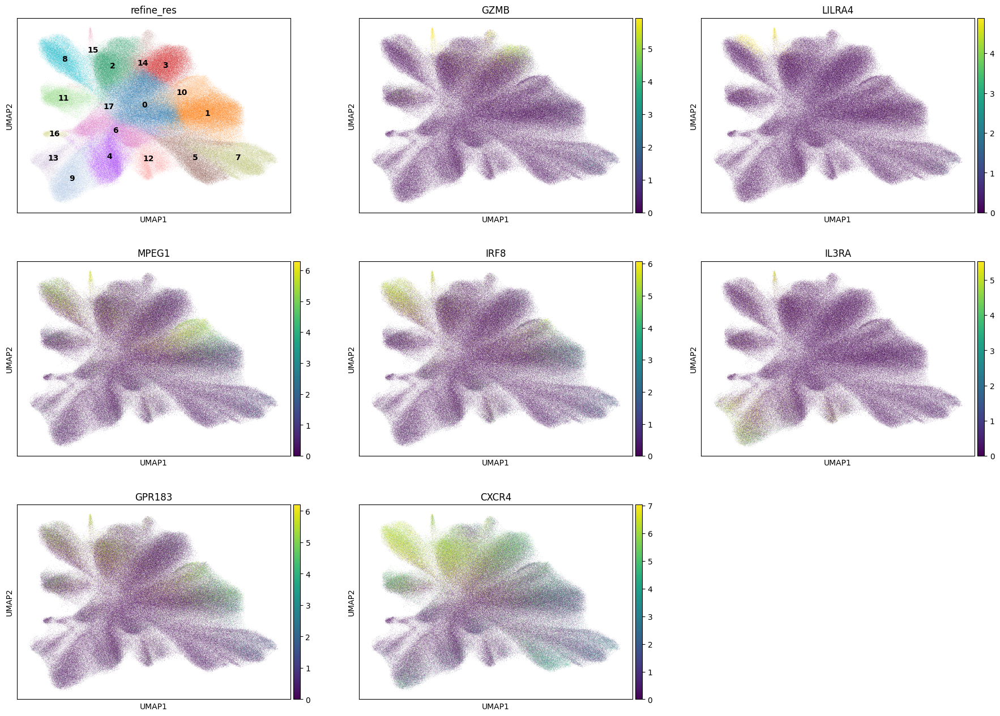

In [104]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [105]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 15: 2188
Percentage of cells in cluster 15: 0.5


In [106]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'pDC'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'pDC'

### 5.17. Cluster 16

In [107]:
cluster_id = '16'

In [108]:
top_ranked_genes[cluster_id]

0      ACTA2
1      MYH11
2       MYLK
3        DES
4       CNN1
5      ACTG2
6    ADAMTS1
Name: 16, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


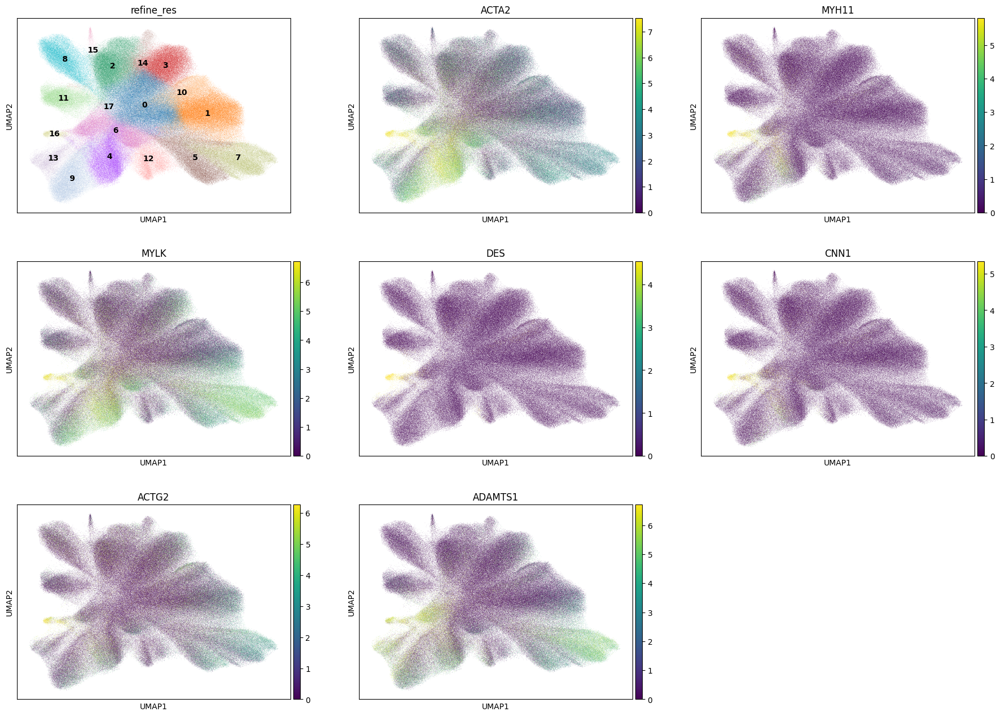

In [109]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [110]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 16: 2107
Percentage of cells in cluster 16: 0.5


In [111]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Smooth_muscle'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Smooth_muscle'

### 5.18. Cluster 17

In [112]:
cluster_id = '17'

In [113]:
top_ranked_genes[cluster_id]

0        KIT
1       CPA3
2     IL1RL1
3      MS4A2
4      GATA2
5      VWA5A
6    SLC18A2
Name: 17, dtype: object

... storing 'label1' as categorical
... storing 'label2' as categorical


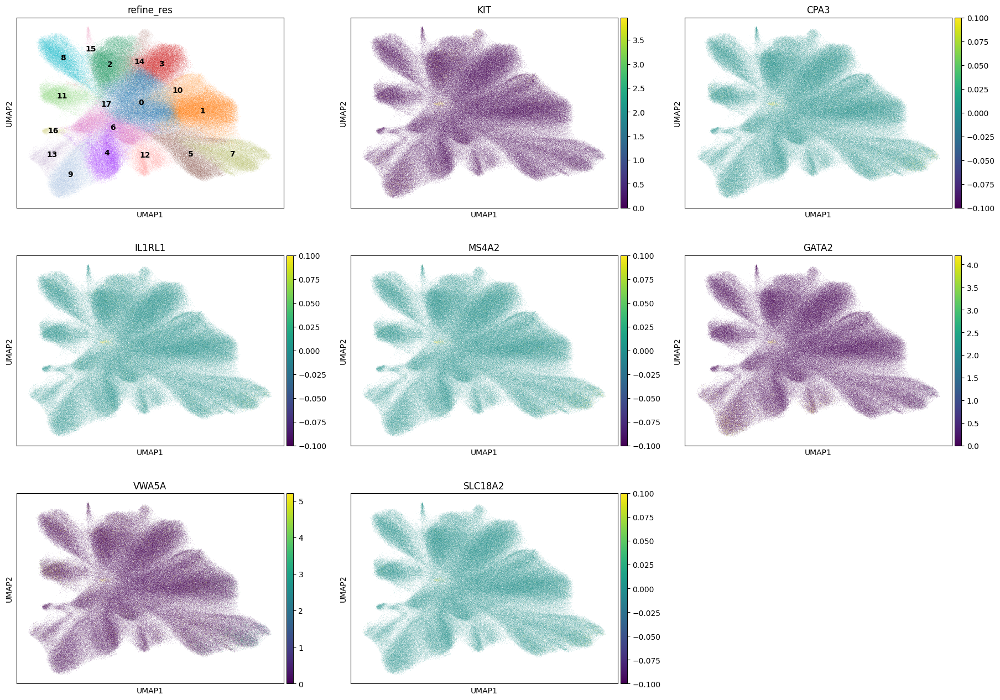

In [114]:
sc.pl.umap(adata_cells, color=[clustering_label]+list_genes[int(cluster_id)*7:int(cluster_id)*7+7], vmax="p99", vmin=0, ncols=3, legend_loc='on data')

In [115]:
print(f"Number of cells in cluster {cluster_id}: {len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id])}")
print(f"Percentage of cells in cluster {cluster_id}: {round(len(adata_cells.obs[clustering_label][adata_cells.obs[clustering_label]==cluster_id]) / len(adata_cells.obs[clustering_label]) * 100, 1)}")

Number of cells in cluster 17: 296
Percentage of cells in cluster 17: 0.1


In [116]:
adata_cells.obs['label1'] = adata_cells.obs['label1'].astype('str')
adata_cells.obs['label2'] = adata_cells.obs['label2'].astype('str')

adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label1'] = 'Mast'
adata_cells.obs.loc[adata_cells.obs['refine_res'] == cluster_id, 'label2'] = 'Mast'

## 6. Cancer cells

... storing 'label1' as categorical
... storing 'label2' as categorical


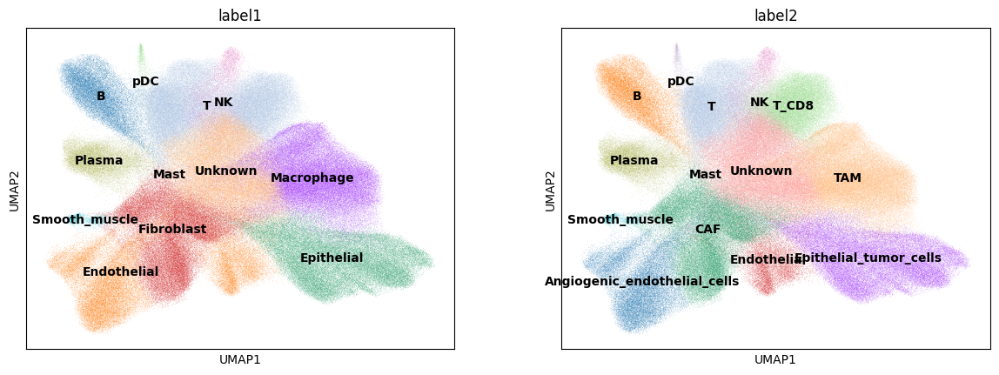

In [117]:
sc.pl.umap(adata_cells, color=['label1', 'label2'], vmax="p99", vmin=0, ncols=4, legend_loc='on data')

In [118]:
# Cancer cells
adata_cells.obs['label3'] = 'normal_cell'
adata_cells.obs.loc[adata_cells.obs['label1'] == 'Epithelial', 'label3'] = 'cancer_cell'

... storing 'label3' as categorical


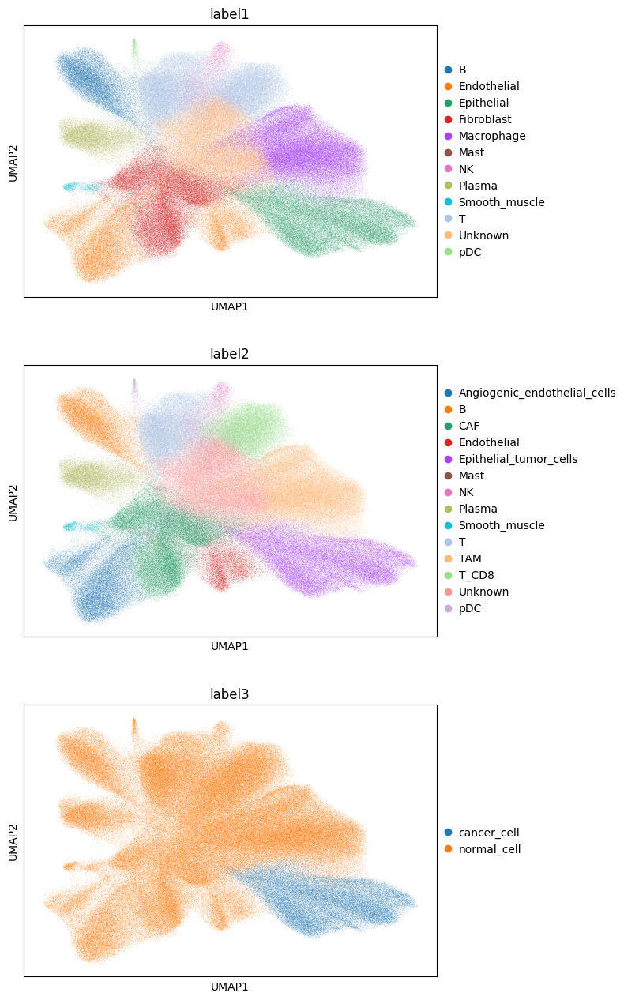

In [119]:
sc.pl.umap(adata_cells, color=['label1', 'label2', 'label3'], ncols=1)

## 7. Save

In [120]:
adata_cells.obs

,cell_id,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,nucleus_count,segmentation_method,region,z_level,pca_n10_pcs24_leiden_res0.6,pca_n10_pcs24_leiden_res0.8,refine_res,label1,label2,label3
0,aaaaaaaa-1,75,0,0,0,0,0,75,59.019221,31.970626,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0,0,0,0,Unknown,Unknown,normal_cell
1,aaaaaaab-1,71,0,0,0,0,0,71,85.029222,46.149689,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0,12,14,14,NK,NK,normal_cell
2,aaaaaaac-1,96,0,0,0,0,0,96,64.302502,40.730939,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0,4,3,3,T,T_CD8,normal_cell
3,aaaaaaad-1,154,0,0,0,0,0,154,134.746255,67.508596,2.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0,7,5,5,Epithelial,Epithelial_tumor_cells,cancer_cell
4,aaaaaaae-1,28,0,0,0,0,0,28,34.680001,21.268595,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels,0.0,0,0,0,Unknown,Unknown,normal_cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
465519,aaahacaj-1,18,0,0,0,0,0,18,23.752188,16.482032,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0,2,4,4,Fibroblast,CAF,normal_cell
465520,aaahacak-1,13,0,0,0,0,0,13,38.202189,7.766875,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0,1,10,10,Macrophage,TAM,normal_cell
465521,aaahacal-1,43,0,0,0,0,0,43,45.788439,11.334219,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,5.0,2,0,0,Unknown,Unknown,normal_cell
465528,aaahacbc-1,32,0,0,0,0,0,32,32.060939,32.060939,1.0,Segmented by nucleus expansion of 5.0µm,cell_labels,4.0,0,0,0,Unknown,Unknown,normal_cell


In [ ]:
adata_annots_cells_path = get_full_path("STHELAR_HistoST", "adata_annots_cells", f"adata_annots_cells_{slide_id}.h5ad", as_str=True)
adata_cells.write_h5ad(adata_annots_cells_path)
# adata_cells = sc.read_h5ad(adata_annots_cells_path)